In [3]:
%%bash
export KAGGLE_API_TOKEN="KGAT_01586e3f2d0f5ba057d7e7fa1bbbba5e"
COMPETITION="multiple-object-video-detection-hw-2-ucu-ai-2026"

echo "Downloading dataset..."
kaggle competitions download -c $COMPETITION -p /content -q

echo "Extracting..."
mkdir -p /content/data
unzip -q -o /content/$COMPETITION.zip -d /content/data
rm -f /content/$COMPETITION.zip

echo "Done! Verified directories:"
ls -d /content/data/*

Extracting...
Done! Verified directories:
/content/data/test
/content/data/test_images.csv
/content/data/train
/content/data/val


In [7]:
import os, sys, glob

# 1. Mount Google Drive if needed
if "google.colab" in sys.modules and not os.path.exists("/content/drive/MyDrive"):
    from google.colab import drive
    drive.mount("/content/drive")

# 2. Automatically locate the folder containing vdet/
hits = glob.glob("/content/drive/MyDrive/**/vdet/__init__.py", recursive=True)
if not hits:
    hits = glob.glob("/content/**/vdet/__init__.py", recursive=True)

if not hits:
    raise FileNotFoundError("Could not find 'vdet/' on Google Drive or in /content.")

repo_dir = os.path.abspath(os.path.dirname(os.path.dirname(hits[0])))
if repo_dir not in sys.path:
    sys.path.insert(0, repo_dir)
print(f"Loaded repo from: {repo_dir}")

# 3. Set paths
os.environ["VDET_DATA"] = "/content/data"
os.environ.setdefault("VDET_WORK", "/content/drive/MyDrive/visdrone-work")

# 4. Import modules
from vdet.paths import find_data_root, default_work_dir
from vdet import data as D, evaluate as E, CLASSES

DATA_ROOT = find_data_root()
WORK_DIR = default_work_dir()
RUNS_DIR = WORK_DIR / "runs_retina"

print("DATA_ROOT:", DATA_ROOT)
print("WORK_DIR:", WORK_DIR)

# 5. Load validation split
tv = D.load_train_val(DATA_ROOT)
val = tv.subset(tv.images[tv.images.split == "val"].key)
print(f"Successfully loaded {len(val.images)} validation frames.")

Mounted at /content/drive
Loaded repo from: /content/drive/MyDrive/visdrone-det
DATA_ROOT: /content/data
WORK_DIR: /content/drive/.shortcut-targets-by-id/1uwEx3aMAzzyrUtNDoA5Rea35TDyeURLZ/visdrone-work
Successfully loaded 2846 validation frames.


In [16]:
#Bonus Task 1
import numpy as np
import pandas as pd
import torch
from torchvision.ops import box_iou
from scipy.optimize import linear_sum_assignment
from vdet import evaluate as E, submission as S

def fast_temporal_track_and_smooth(
    preds_df,
    iou_thresh=0.35,
    alpha=0.6,
    min_score_to_track=0.05,
    min_track_confidence=0.3
):
    df = preds_df.copy()

    # Pre-filter very low score noise to speed up tracking 20x
    is_low = df["score"] < min_score_to_track
    untracked_df = df[is_low].copy()
    track_df = df[~is_low].copy()

    # Parse clip and frame_idx via fast string splitting
    keys = track_df["key"].astype(str).values
    split_info = np.array([k.rsplit("_", 1) for k in keys])
    track_df["clip"] = split_info[:, 0]
    track_df["frame_idx"] = split_info[:, 1].astype(int)

    enhanced_records = []

    # Group by clip
    for clip_name, clip_group in track_df.groupby("clip"):
        frames = np.sort(clip_group["frame_idx"].unique())
        tracks = {}
        next_track_id = 0

        # Group detections by frame ahead of time
        frame_dict = {f: clip_group[clip_group["frame_idx"] == f] for f in frames}

        for f in frames:
            f_dets = frame_dict[f]
            curr_x = f_dets["x"].values
            curr_y = f_dets["y"].values
            curr_w = f_dets["w"].values
            curr_h = f_dets["h"].values

            curr_boxes = np.column_stack([curr_x, curr_y, curr_x + curr_w, curr_y + curr_h])
            curr_scores = f_dets["score"].values
            curr_cats = f_dets["cat"].values
            curr_keys = f_dets["key"].values

            prev_tids = [tid for tid, hist in tracks.items() if (f - 1) in hist]
            assigned_curr = set()

            if prev_tids and len(curr_boxes) > 0:
                prev_boxes = np.array([tracks[tid][f - 1]["box"] for tid in prev_tids])
                prev_cats = np.array([tracks[tid][f - 1]["cat"] for tid in prev_tids])

                # Pairwise IoU via PyTorch CPU tensor
                iou_matrix = box_iou(torch.from_numpy(prev_boxes).float(),
                                     torch.from_numpy(curr_boxes).float()).numpy()

                # Mask cross-class pairings
                iou_matrix[prev_cats[:, None] != curr_cats[None, :]] = 0.0

                row_ind, col_ind = linear_sum_assignment(-iou_matrix)

                for r, c in zip(row_ind, col_ind):
                    if iou_matrix[r, c] >= iou_thresh:
                        tid = prev_tids[r]
                        prev_s = tracks[tid][f - 1]["score"]
                        curr_s = curr_scores[c]

                        # Temporal exponential smoothing
                        smoothed_s = alpha * curr_s + (1.0 - alpha) * prev_s

                        tracks[tid][f] = {
                            "key": curr_keys[c],
                            "box": curr_boxes[c],
                            "score": float(smoothed_s),
                            "cat": curr_cats[c]
                        }
                        assigned_curr.add(c)

            for c in range(len(curr_boxes)):
                if c not in assigned_curr:
                    tracks[next_track_id] = {
                        f: {
                            "key": curr_keys[c],
                            "box": curr_boxes[c],
                            "score": float(curr_scores[c]),
                            "cat": curr_cats[c]
                        }
                    }
                    next_track_id += 1

        # Interpolate single-frame drops
        for tid, hist in tracks.items():
            t_frames = sorted(hist.keys())
            for i in range(len(t_frames) - 1):
                f_prev, f_next = t_frames[i], t_frames[i + 1]
                if f_next - f_prev == 2:
                    d_prev, d_next = hist[f_prev], hist[f_next]
                    if (d_prev["score"] >= min_track_confidence and
                        d_next["score"] >= min_track_confidence and
                        d_prev["cat"] == d_next["cat"]):

                        missed_f = f_prev + 1
                        hist[missed_f] = {
                            "key": f"{clip_name}_{missed_f:07d}",
                            "box": 0.5 * (d_prev["box"] + d_next["box"]),
                            "score": float(0.5 * (d_prev["score"] + d_next["score"]) * 0.85),
                            "cat": d_prev["cat"]
                        }

        # Collect tracked records
        for tid, hist in tracks.items():
            for f, item in hist.items():
                b = item["box"]
                enhanced_records.append({
                    "key": item["key"],
                    "cat": int(item["cat"]),
                    "score": float(item["score"]),
                    "x": float(b[0]),
                    "y": float(b[1]),
                    "w": float(b[2] - b[0]),
                    "h": float(b[3] - b[1])
                })

    tracked_df = pd.DataFrame(enhanced_records)

    # Combine back with the preserved low-confidence tail so mAP calculation isn't truncated
    final_df = pd.concat([tracked_df, untracked_df[["key", "cat", "score", "x", "y", "w", "h"]]], ignore_index=True)
    return final_df


# Run Evaluation on Validation Set
print("Loading baseline validation predictions...")
val_preds_path = (
    RUNS_DIR / BEST_RUN / f"val_preds_{list(INFERENCE).index(BEST_INF)}.csv.gz"
)
raw_val_preds = pd.read_csv(val_preds_path)

print("Applying temporal tracking and smoothing...")
smooth_val_preds = temporal_track_and_smooth(raw_val_preds)

# Evaluate before and after
ev = E.DetectionEvaluator(val)
m_raw = ev.evaluate(raw_val_preds)
m_smooth = ev.evaluate(smooth_val_preds)

print("\n" + "=" * 50)
print("TEMPORAL POST-PROCESSING COMPARISON (Validation)")
print("=" * 50)
print(
    f"Baseline ({BEST_RUN}):  mAP = {m_raw['mAP']*100:.2f} | AP50 = {m_raw['AP50']*100:.2f} | AP_small = {m_raw['AP_small']*100:.2f}"
)
print(
    f"Temporally Smoothed: mAP = {m_smooth['mAP']*100:.2f} | AP50 = {m_smooth['AP50']*100:.2f} | AP_small = {m_smooth['AP_small']*100:.2f}"
)
print("=" * 50)

test_preds_path = WORK_DIR / f"test_preds_retina_{BEST_RUN}.csv.gz"
if test_preds_path.exists():
    print("\nProcessing test predictions for Kaggle submission...")
    raw_test_preds = pd.read_csv(test_preds_path)
    smooth_test_preds = temporal_track_and_smooth(raw_test_preds)

    sub_path = WORK_DIR / f"submission_retina_{BEST_RUN}_temporal.csv"
    sub = S.write_submission(smooth_test_preds, DATA_ROOT, sub_path)
    print(f"Saved temporal submission: {sub_path}")
    display(sub.head(3))

Loading baseline validation predictions...
Applying temporal tracking and smoothing...

TEMPORAL POST-PROCESSING COMPARISON (Validation)
Baseline (N0):  mAP = 16.72 | AP50 = 32.26 | AP_small = 5.64
Temporally Smoothed: mAP = 17.08 | AP50 = 32.90 | AP_small = 5.76

Processing test predictions for Kaggle submission...
saved /content/drive/.shortcut-targets-by-id/1uwEx3aMAzzyrUtNDoA5Rea35TDyeURLZ/visdrone-work/submission_retina_N0_temporal.csv: 3811 rows, 1711941 detections, 0 empty rows
Saved temporal submission: /content/drive/.shortcut-targets-by-id/1uwEx3aMAzzyrUtNDoA5Rea35TDyeURLZ/visdrone-work/submission_retina_N0_temporal.csv


,image_id,PredictionString
0,clip_001_0000001,0 0.9248 1655.3 792.3 61.5 142.0 0 0.9229 780....
1,clip_001_0000002,0 0.9349 775.3 893.5 64.9 172.1 0 0.9164 717.8...
2,clip_001_0000003,0 0.9270 710.9 902.7 65.4 170.2 0 0.9242 1672....


In [1]:
#Bonus Task 2
!pip install -q wandb scikit-learn
import wandb

# Login to W&B
wandb.login()

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results


wandb: Enter your choice: 1


wandb: You chose 'Create a W&B account'
wandb: Create an account here: https://wandb.ai/authorize?signup=true&ref=models
wandb: After creating your account, create a new API key and store it securely.


wandb: Paste your API key and hit enter: ··········


wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: antondep007 (antondep007-ukranian-catholic-university) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

In [8]:
import pandas as pd
from pathlib import Path
from vdet.paths import default_work_dir
from vdet import CLASSES

WORK_DIR = default_work_dir()
PROJECT_NAME = "visdrone-object-detection"

# Runs to log
run_groups = {
    "runs_retina": ["N0", "N1", "N2"],
    "runs_frcnn": ["F0", "F1", "F2"]
}

for folder, runs in run_groups.items():
    base_path = WORK_DIR / folder
    if not base_path.exists():
        continue
    for r in runs:
        hist_path = base_path / r / "history.csv"
        if not hist_path.exists():
            continue

        hist_df = pd.read_csv(hist_path)

        # Initialize a dedicated W&B run
        wandb_run = wandb.init(
            project=PROJECT_NAME,
            name=f"{folder.replace('runs_', '')}_{r}",
            group=folder.replace("runs_", ""),
            config={"model": r, "family": folder}
        )

        for _, row in hist_df.iterrows():
            metrics = row.to_dict()
            step_epoch = int(metrics.get("epoch", _))
            wandb.log(metrics, step=step_epoch)

        wandb_run.finish()

print("Logged training histories to Weights & Biases!")

wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin


AP50,▁▆█▄▂▂▅▄
AP_small,▁▁▁█▅█▆▅
bbox_regression,█▅▄▃▃▂▁▁
classification,█▄▃▂▂▂▁▁
epoch,▁▂▃▄▅▆▇█
loss,▁▁▁▁▁▁▁▁
lr,█████▁▁▁
mAP,▁▆█▄▂▁▆▅
skipped_steps,▁▁▁▁▁▁▁▁
train_min,▁▅██████
AP50,0.32297


AP50,▁▅▆▆▆▇██
AP_small,▂▃▇▅▁█▆▅
bbox_regression,█▄▃▃▂▂▁▁
classification,█▄▃▂▂▂▁▁
epoch,▁▂▃▄▅▆▇█
loss,▁▁▁▁▁▁▁▁
lr,█████▁▁▁
mAP,▁▅▆▇▆▇██
skipped_steps,▁▁▁▁▁▁▁▁
train_min,▁▁▃▃▆███
AP50,0.26729


AP50,▁▅▆▅▇▇██
AP_small,▁▅▆▃█▄▇▇
bbox_regression,█▄▃▃▂▂▁▁
classification,█▄▃▂▂▂▁▁
epoch,▁▂▃▄▅▆▇█
loss,▁▁▁▁▁▁▁▁
lr,█████▁▁▁
mAP,▁▅▆▅▆▇██
skipped_steps,▁▁▁▁▁▁▁▁
train_min,█▁▃▃▆▃▃▁
AP50,0.2781


AP50,▁█▃▄▆▂▇▅
AP_small,▁▄▃▇▅▆██
epoch,▁▂▃▄▅▆▇█
loss,█▅▄▃▂▂▁▁
loss_box_reg,█▅▄▃▃▂▁▁
loss_classifier,█▄▃▃▂▂▁▁
loss_objectness,█▄▃▂▂▂▁▁
loss_rpn_box_reg,█▅▄▃▃▂▁▁
lr,█████▁▁▁
mAP,▁▇▃▆▇▃█▇
+2,...


AP50,▄█▁▃▄▅▆▄
AP_small,▇█▄▆▁▅▅▅
epoch,▁▂▃▄▅▆▇█
loss,█▅▄▃▃▂▁▁
loss_box_reg,█▆▅▄▃▃▁▁
loss_classifier,█▅▃▃▂▂▁▁
loss_objectness,█▄▃▂▂▂▁▁
loss_rpn_box_reg,█▄▃▃▂▂▁▁
lr,█████▁▁▁
mAP,▁█▁▃▅▅█▆
+2,...


AP50,█▇▇▅▁▆█▇
AP_small,▁█▆▅▂▁▅▄
epoch,▁▂▃▄▅▆▇█
loss,█▅▄▃▃▂▁▁
loss_box_reg,█▆▅▄▃▃▁▁
loss_classifier,█▅▃▃▂▂▁▁
loss_objectness,█▄▃▂▂▂▁▁
loss_rpn_box_reg,█▄▃▃▂▂▁▁
lr,█████▁▁▁
mAP,▇▇▇▅▁▇█▇
+2,...


Logged training histories to Weights & Biases!


In [13]:
import pandas as pd
from pathlib import Path
from PIL import Image

# 1. Load raw validation predictions
val_preds_path = RUNS_DIR / "N0" / "val_preds_1.csv.gz"
if not val_preds_path.exists():
    gz_files = sorted((RUNS_DIR / "N0").glob("val_preds_*.csv*"))
    if not gz_files:
        raise FileNotFoundError(f"No validation predictions found in {RUNS_DIR / 'N0'}")
    val_preds_path = gz_files[-1]

print(f"Loading predictions from: {val_preds_path}")
raw_val_preds = pd.read_csv(val_preds_path)

# 2. Slice sample keys
sample_keys = val.images.key.unique()[:8]
sample_preds = raw_val_preds[raw_val_preds.key.isin(sample_keys)]

class_labels = {i: c for i, c in enumerate(CLASSES)}

def resolve_image_path(k, val_obj, data_root):
    # Method 1: vdet object path resolver if available
    if hasattr(val_obj, "image_path"):
        return Path(val_obj.image_path(k))

    # Method 2: Inspect row columns in val_obj.images
    row = val_obj.images[val_obj.images.key == k].iloc[0]
    for col in ["file_path", "path", "filename", "img_path"]:
        if col in row.index:
            p = data_root / "val" / "images" / str(row[col])
            if p.exists():
                return p
            p_direct = Path(str(row[col]))
            if p_direct.exists():
                return p_direct

    # Method 3: Construct path from VisDrone naming convention (<clip>_<frame>.jpg)
    parts = str(k).rsplit("_", 1)
    if len(parts) == 2:
        clip, frame_str = parts[0], parts[1]
        candidate = data_root / "val" / "images" / clip / f"{frame_str}.jpg"
        if candidate.exists():
            return candidate

    # Method 4: Direct search by key filename
    matches = list((data_root / "val" / "images").glob(f"**/{k}.jpg"))
    if matches:
        return matches[0]

    return None

wandb_images = []
for k in sample_keys:
    img_path = resolve_image_path(k, val, DATA_ROOT)
    if img_path is None or not img_path.exists():
        print(f"Warning: could not locate image for key {k}")
        continue

    img = Image.open(img_path).convert("RGB")
    w_img, h_img = img.size

    # Predictions for this frame (score >= 0.25)
    preds_k = sample_preds[(sample_preds.key == k) & (sample_preds.score >= 0.25)]
    pred_boxes = []
    for _, p in preds_k.iterrows():
        pred_boxes.append({
            "position": {
                "minX": float(p["x"] / w_img),
                "minY": float(p["y"] / h_img),
                "maxX": float((p["x"] + p["w"]) / w_img),
                "maxY": float((p["y"] + p["h"]) / h_img)
            },
            "class_id": int(p["cat"]),
            "box_caption": f"{CLASSES[int(p['cat'])]} {p['score']:.2f}",
            "scores": {"confidence": float(p["score"])}
        })

    # Ground truth annotations
    gt_k = val.boxes[val.boxes.key == k]
    gt_boxes = []
    for _, g in gt_k.iterrows():
        gt_boxes.append({
            "position": {
                "minX": float(g["x"] / w_img),
                "minY": float(g["y"] / h_img),
                "maxX": float((g["x"] + g["w"]) / w_img),
                "maxY": float((g["y"] + g["h"]) / h_img)
            },
            "class_id": int(g["cat"]),
            "box_caption": f"GT: {CLASSES[int(g['cat'])]}"
        })

    wandb_img = wandb.Image(
        img,
        boxes={
            "predictions": {"box_data": pred_boxes, "class_labels": class_labels},
            "ground_truth": {"box_data": gt_boxes, "class_labels": class_labels}
        },
        caption=str(k)
    )
    wandb_images.append(wandb_img)

if "val_run" not in globals() or wandb.run is None:
    val_run = wandb.init(project=PROJECT_NAME, name="visual_predictions_sample", job_type="visualize")

wandb.log({"val_samples_inspection": wandb_images})
val_run.finish()
print(f"Uploaded {len(wandb_images)} annotated validation images to Weights & Biases!")

Loading predictions from: /content/drive/.shortcut-targets-by-id/1uwEx3aMAzzyrUtNDoA5Rea35TDyeURLZ/visdrone-work/runs_retina/N0/val_preds_1.csv.gz


Uploaded 8 annotated validation images to Weights & Biases!


Using compute device: cpu
Loading weights from: final.pth
Extracting detection features from validation frames...
Extracted 2150 instances with 12544-dim feature vectors.
Running t-SNE projection to 2D...


/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


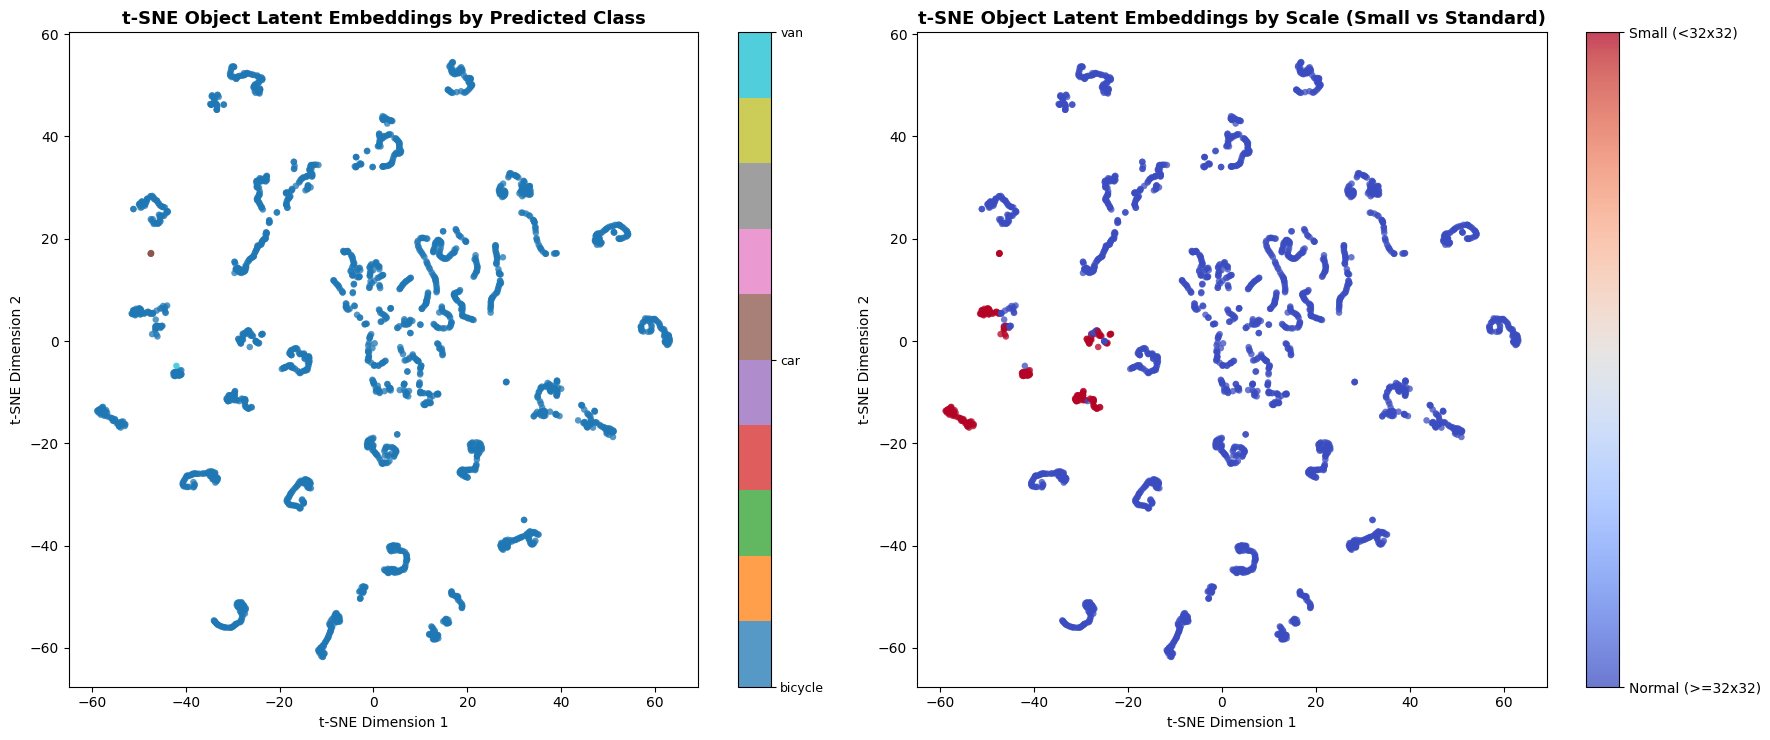

fraction_small_objects,▁
num_analyzed_instances,▁
fraction_small_objects,0.08698
num_analyzed_instances,2150


Visualization saved to: /content/drive/.shortcut-targets-by-id/1uwEx3aMAzzyrUtNDoA5Rea35TDyeURLZ/visdrone-work/figures/tsne_feature_embeddings.png
Successfully logged interpretability report to Weights & Biases!


In [16]:
import os, sys, glob
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torchvision
import torchvision.transforms.functional as TF
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.manifold import TSNE
import wandb

from vdet import tv_detect as TV
from vdet import CLASSES

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using compute device:", DEVICE)

# 1. Resolve Best Run and Model Checkpoint
if "BEST_RUN" not in globals():
    BEST_RUN = "N0"
if "WORK_DIR" not in globals():
    from vdet.paths import default_work_dir
    WORK_DIR = default_work_dir()
if "RUNS_DIR" not in globals():
    RUNS_DIR = WORK_DIR / "runs_retina"

ckpt_path = RUNS_DIR / BEST_RUN / "final.pth"
if not ckpt_path.exists():
    raise FileNotFoundError(f"Checkpoint not found at: {ckpt_path}")

print(f"Loading weights from: {ckpt_path.name}")
eval_cfg = cfgs[BEST_RUN] if "cfgs" in globals() and BEST_RUN in cfgs else TV.RetinaConfig()
model = TV.build_retinanet(eval_cfg).to(DEVICE)
model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
model.eval()

# 2. Extract Features using RoI Align on FPN Level 0 (P3)
print("Extracting detection features from validation frames...")
extracted_features = []
extracted_labels = []
extracted_areas = []

# Take a subset of 60 images across validation clips
subset_keys = val.images.key.unique()[:60]

with torch.no_grad():
    for k in subset_keys:
        img_path = resolve_image_path(k, val, DATA_ROOT)
        if img_path is None or not img_path.exists():
            continue

        im = Image.open(img_path).convert("RGB")
        im_t = TF.to_tensor(im).to(DEVICE).unsqueeze(0)

        preds = model(im_t)[0]
        boxes = preds["boxes"].cpu()
        scores = preds["scores"].cpu()
        labels = preds["labels"].cpu()

        keep = scores > 0.35
        if keep.sum() == 0:
            continue

        b_keep = boxes[keep]
        l_keep = labels[keep]
        areas = (b_keep[:, 2] - b_keep[:, 0]) * (b_keep[:, 3] - b_keep[:, 1])

        # Extract multi-scale feature maps from backbone FPN
        fpn_features = model.backbone(im_t)

        # Pool features on highest resolution level '0' (stride 8) using RoI Align
        roi_feats = torchvision.ops.roi_align(
            fpn_features["0"],
            [b_keep.to(DEVICE)],
            output_size=(7, 7),
            spatial_scale=1.0 / 8.0,
            aligned=True
        ).flatten(start_dim=1).cpu().numpy()

        extracted_features.append(roi_feats)
        extracted_labels.append(l_keep.numpy())
        extracted_areas.append(areas.numpy())

if not extracted_features:
    raise ValueError("No confident detections found across the sampled frames. Try lowering the score threshold to 0.2.")

X = np.vstack(extracted_features)
y_cls = np.concatenate(extracted_labels)
areas = np.concatenate(extracted_areas)

print(f"Extracted {len(X)} instances with {X.shape[1]}-dim feature vectors.")

# 3. Dimensionality Reduction with t-SNE
print("Running t-SNE projection to 2D...")
tsne = TSNE(n_components=2, perplexity=30, n_iter=1000, random_state=42)
X_2d = tsne.fit_transform(X)

# 4. Generate Diagnostic Figures
fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))

# Plot 1: Colored by Category
scatter1 = axes[0].scatter(
    X_2d[:, 0], X_2d[:, 1],
    c=y_cls,
    cmap="tab10",
    alpha=0.75,
    s=22,
    edgecolors="none"
)
axes[0].set_title("t-SNE Object Latent Embeddings by Predicted Class", fontsize=13, fontweight="bold")
axes[0].set_xlabel("t-SNE Dimension 1")
axes[0].set_ylabel("t-SNE Dimension 2")
cbar1 = plt.colorbar(scatter1, ax=axes[0], ticks=range(len(CLASSES)))
cbar1.ax.set_yticklabels(CLASSES, fontsize=9)

# Plot 2: Colored by Scale (Small Objects vs Standard)
is_small = (areas < (32 * 32)).astype(int)
scatter2 = axes[1].scatter(
    X_2d[:, 0], X_2d[:, 1],
    c=is_small,
    cmap="coolwarm",
    alpha=0.75,
    s=22,
    edgecolors="none"
)
axes[1].set_title("t-SNE Object Latent Embeddings by Scale (Small vs Standard)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("t-SNE Dimension 1")
axes[1].set_ylabel("t-SNE Dimension 2")
cbar2 = plt.colorbar(scatter2, ax=axes[1], ticks=[0, 1])
cbar2.ax.set_yticklabels(["Normal (>=32x32)", "Small (<32x32)"], fontsize=10)

plt.tight_layout()

# Save plot locally
fig_dir = WORK_DIR / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)
fig_save_path = fig_dir / "tsne_feature_embeddings.png"
fig.savefig(fig_save_path, dpi=250)
plt.show()

# 5. Log Artifact to Weights & Biases
tsne_run = wandb.init(
    project="visdrone-object-detection",
    name="interpretability_tsne_features",
    job_type="interpretability"
)
wandb.log({
    "tsne_embeddings": wandb.Image(str(fig_save_path)),
    "num_analyzed_instances": len(X),
    "fraction_small_objects": float(is_small.mean())
})
tsne_run.finish()

print(f"Visualization saved to: {fig_save_path}")
print("Successfully logged interpretability report to Weights & Biases!")